# 02 · Grounded VLM extraction (Qwen3.8-27B, vision)

For every section, and every page region of it in order:

1. render the region (150 DPI) and take its **text from the PDF text layer** (with `[Amdt …]` notes removed);
2. Qwen gets both and rewrites the text as Markdown: list items `(a) (1) (i) (A)`, GitHub tables, glossary entries as `- **Term**: definition`, figures as `[Figure omitted: caption]`. The image is used for layout only; the words must come from the text layer;
3. the last lines of the previous region's output are passed along, so lists and tables continue across page breaks;
4. the output is scored against the source text (word recall/precision ≥ 0.995, no missing numbers, no broken Markdown). If it fails, there is one retry with feedback, then a rule-based fallback from the text layer.

Results are cached per region in `data/vlm_cache/` (resumable; delete a file or use `REDO` to re-run). Needs the vLLM container from notebook 00.

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)  # all paths below are relative to the repo root
from dotenv import load_dotenv
load_dotenv(ROOT / ".env")
PDF = ROOT / "cs-e_amendment_9.pdf"   # header/footer already cropped
DATA = ROOT / "data"

In [2]:
import json, time
import pandas as pd, pymupdf
from tqdm.auto import tqdm
from IPython.display import HTML, Image, Markdown, display
from csparse.segment import load_sections, region_png
from csparse.vlm import PROMPT_VERSION, SYSTEM_PROMPT, Extractor, VLMConfig, load_cache

sections = load_sections(DATA / "sections.json")
by_id = {s.section_id: s for s in sections}
cfg = VLMConfig(cache_dir=DATA / "vlm_cache")   # workers=4, dpi=150, thresholds 0.995
ex = Extractor(PDF, cfg)
print(len(sections), "sections,", sum(len(s.regions) for s in sections), "regions | prompt", PROMPT_VERSION)

175 sections, 427 regions | prompt 69eb743dbb


### Parameters
* `PILOT`: sections to try first.
* `RUN_ALL`: extract everything (≈1–1.5 h on the 3090 when starting from an empty cache).
* `REDO`: section ids whose cache is ignored (e.g. after a prompt change; a changed `SYSTEM_PROMPT` re-runs everything automatically).

In [3]:
PILOT = ["CS-E 15", "AMC E 30", "CS-E 790 Appendix A"]
RUN_ALL = True
REDO: set[str] = set()

In [4]:
t0 = time.time()
res = ex.run([by_id[s] for s in PILOT], redo=REDO)
print(f"{time.time() - t0:.0f}s")
for sid in PILOT:
    for r in res[sid]:
        m = r.get("metrics") or {}
        print(f"{sid:22} p{r['page']:<4} {r['status']:10} recall={m.get('recall', 0):.3f} precision={m.get('precision', 0):.3f}")

0s
CS-E 15                p17   ok         recall=1.000 precision=1.000
CS-E 15                p18   ok         recall=1.000 precision=1.000
CS-E 15                p19   ok         recall=1.000 precision=1.000
AMC E 30               p28   ok         recall=1.000 precision=1.000
AMC E 30               p29   ok         recall=1.000 precision=1.000
AMC E 30               p30   ok         recall=1.000 precision=1.000
CS-E 790 Appendix A    p216  ok         recall=1.000 precision=1.000
CS-E 790 Appendix A    p217  retry_ok   recall=1.000 precision=1.000
CS-E 790 Appendix A    p218  retry_ok   recall=1.000 precision=1.000


### Side-by-side review of one region

AMC E 30 region 0 page 28 status=ok {'recall': 1.0, 'precision': 1.0, 'missing': [], 'extra': [], 'issues': []}


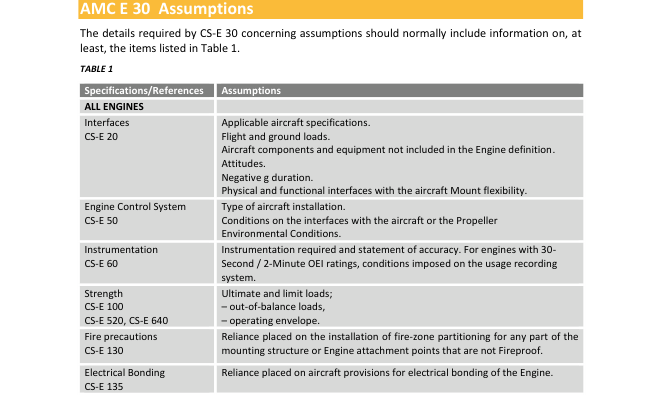

PDF text layer,Markdown
"The details required by CS-E 30 concerning assumptions should normally include information on, at least, the items listed in Table 1. TABLE 1 Specifications/References Assumptions ALL ENGINES Interfaces Applicable aircraft specifications. CS-E 20 Flight and ground loads. Aircraft components and equipment not included in the Engine definition. Attitudes. Negative g duration. Physical and functional interfaces with the aircraft Mount flexibility. Engine Control System Type of aircraft installation. CS-E 50 Conditions on the interfaces with the aircraft or the Propeller Environmental Conditions. Instrumentation Instrumentation required and statement of accuracy. For engines with 30- CS-E 60 Second / 2-Minute OEI ratings, conditions imposed on the usage recording system. Strength Ultimate and limit loads; CS-E 100 – out-of-balance loads, CS-E 520, CS-E 640 – operating envelope. Fire precautions Reliance placed on the installation of fire-zone partitioning for any part of the CS-E 130 mounting structure or Engine attachment points that are not Fireproof. Electrical Bonding Reliance placed on aircraft provisions for electrical bonding of the Engine. CS-E 135","The details required by CS-E 30 concerning assumptions should normally include information on, at least, the items listed in Table 1. TABLE 1 | Specifications/References | Assumptions | |---|---| | **ALL ENGINES** | | | Interfaces CS-E 20 | Applicable aircraft specifications. Flight and ground loads. Aircraft components and equipment not included in the Engine definition. Attitudes. Negative g duration. Physical and functional interfaces with the aircraft Mount flexibility. | | Engine Control System CS-E 50 | Type of aircraft installation. Conditions on the interfaces with the aircraft or the Propeller Environmental Conditions. | | Instrumentation CS-E 60 | Instrumentation required and statement of accuracy. For engines with 30-Second / 2-Minute OEI ratings, conditions imposed on the usage recording system. | | Strength CS-E 100 CS-E 520, CS-E 640 | Ultimate and limit loads; – out-of-balance loads, – operating envelope. | | Fire precautions CS-E 130 | Reliance placed on the installation of fire-zone partitioning for any part of the mounting structure or Engine attachment points that are not Fireproof. | | Electrical Bonding CS-E 135 | Reliance placed on aircraft provisions for electrical bonding of the Engine. |"


In [5]:
doc = pymupdf.open(PDF)

def show(section_id, idx=0, attempt=None):
    s = by_id[section_id]
    r = json.loads(ex.cache_path(s, idx).read_text())
    md = r["markdown"] if attempt is None else r["attempts"][attempt]["markdown"]
    print(f"{section_id} region {idx} page {r['page']} status={r['status']}", {k: v for k, v in (r.get("metrics") or {}).items() if k in ("recall", "precision", "missing", "extra", "issues")})
    display(Image(region_png(doc, s.regions[idx], dpi=80)))
    display(HTML(f"<table><tr><th>PDF text layer</th><th>Markdown</th></tr><tr>"
                 f"<td style='vertical-align:top;text-align:left'><pre style='white-space:pre-wrap;font-size:11px'>{r['source']}</pre></td>"
                 f"<td style='vertical-align:top;text-align:left'><pre style='white-space:pre-wrap;font-size:11px'>{md}</pre></td></tr></table>"))

show("AMC E 30", 0)

### Full run

In [6]:
if RUN_ALL:
    t0 = time.time()
    with tqdm(total=len(sections), desc="sections") as bar:
        res = ex.run(sections, redo=REDO, progress=bar)
    print(f"done in {(time.time() - t0) / 60:.1f} min")

sections:   0%|          | 0/175 [00:00<?, ?it/s]

done in 0.9 min


### Re-score the cache (no model calls)
`rescore_cache` re-applies the current scoring rules to cached fallbacks and promotes an attempt that now passes. Use it after you change the scoring code in `csparse/vlm.py` (`fidelity`, `markdown_issues`, `judge`). The `ok_fig` status means the output contains a `[Figure omitted]` placeholder and drops words that sit inside a vector-drawn figure. These regions stay listed in the flags for review.

In [7]:
from csparse.vlm import rescore_cache
print("upgraded:", rescore_cache(cfg.cache_dir, cfg))

upgraded: []


### Run summary and flags
`flags.csv` lists every region that needed a retry, fell back to the text layer, or errored. Fallback regions keep all the words but lose table/list structure; review them with `show()` and, if needed, re-run with `REDO`.

In [8]:
cache = load_cache(cfg.cache_dir, sections)
rows = []
for s in sections:
    for idx, r in enumerate(cache[s.section_id]):
        if r is None:
            rows.append(dict(section_id=s.section_id, idx=idx, page=s.regions[idx].page, status="missing"))
            continue
        m = r.get("metrics") or {}
        att = r.get("attempts", [])
        rows.append(dict(section_id=s.section_id, idx=idx, page=r["page"], status=r["status"], attempts=len(att),
                         recall=m.get("recall"), precision=m.get("precision"),
                         seconds=sum(a["seconds"] for a in att), out_tokens=sum(a["completion_tokens"] or 0 for a in att),
                         issues="; ".join(m.get("issues") or []), missing=" ".join(m.get("missing") or [])))
runs = pd.DataFrame(rows)
print(runs.status.value_counts().to_dict())
print(f"VLM time {runs.seconds.sum() / 60:.1f} min (summed over requests), {runs.out_tokens.sum():,} output tokens")
flags = runs[~runs.status.isin(["ok", "empty"])]
flags.to_csv(DATA / "flags.csv", index=False)
flags

{'ok': 379, 'empty': 34, 'retry_ok': 12, 'ok_fig': 1, 'figure_only': 1}
VLM time 222.7 min (summed over requests), 145,119 output tokens


,section_id,idx,page,status,attempts,recall,precision,seconds,out_tokens,issues,missing
9,AMC E 20,0,20,retry_ok,2,1.000000,1.0,102.17,1127,,
57,AMC E 80,1,47,retry_ok,2,1.000000,1.0,130.63,1397,,
132,CS-E 430,1,78,retry_ok,2,1.000000,1.0,42.96,423,,
214,AMC E 650,1,125,retry_ok,2,1.000000,1.0,119.02,1245,,
270,AMC E 740(c)(4),5,161,retry_ok,2,1.000000,1.0,57.76,544,,
271,AMC E 740(c)(4),6,162,ok_fig,2,0.706122,1.0,49.06,476,,the test damage 0 accumulated 7 endurance seve...
278,AMC E 740(c)(4),13,169,figure_only,0,NaN,NaN,0.00,0,,
314,AMC E 780,10,193,retry_ok,2,1.000000,1.0,113.26,1294,,
322,CS-E 790,0,200,retry_ok,2,1.000000,1.0,115.93,1303,,
336,AMC E 790(a)(2),9,211,retry_ok,2,1.000000,1.0,77.14,904,,
